In [1]:
import os
import pandas as pd

# Check files in the current folder
files = sorted([f for f in os.listdir('.') if f.endswith('.csv')])
print(f"Total CSVs found: {len(files)}")

for f in files:
    df = pd.read_csv(f)
    print(f"✓ {f:<30} | Rows: {df.shape[0]:<7} | Cols: {df.shape[1]}")

Total CSVs found: 10
✓ 01_fund_master.csv             | Rows: 40      | Cols: 15
✓ 02_nav_history.csv             | Rows: 46000   | Cols: 3
✓ 03_aum_by_fund_house.csv       | Rows: 90      | Cols: 5
✓ 04_monthly_sip_inflows.csv     | Rows: 48      | Cols: 6
✓ 05_category_inflows.csv        | Rows: 144     | Cols: 3
✓ 06_industry_folio_count.csv    | Rows: 21      | Cols: 6
✓ 07_scheme_performance.csv      | Rows: 40      | Cols: 19
✓ 08_investor_transactions.csv   | Rows: 32778   | Cols: 13
✓ 09_portfolio_holdings.csv      | Rows: 322     | Cols: 8
✓ 10_benchmark_indices.csv       | Rows: 8050    | Cols: 3


In [3]:
import sqlite3

conn = sqlite3.connect("mf_analytics.db")
cur = conn.cursor()

# Dimension: Funds Master
cur.execute("""
CREATE TABLE IF NOT EXISTS dim_fund (
    scheme_code INTEGER PRIMARY KEY,
    scheme_name TEXT NOT NULL,
    amc_name TEXT NOT NULL,
    category TEXT NOT NULL,
    sub_category TEXT,
    benchmark TEXT,
    risk_level TEXT
);
""")

# Fact: Daily NAV History
cur.execute("""
CREATE TABLE IF NOT EXISTS fact_nav (
    nav_id INTEGER PRIMARY KEY AUTOINCREMENT,
    scheme_code INTEGER NOT NULL,
    nav_date DATE NOT NULL,
    nav REAL NOT NULL,
    FOREIGN KEY (scheme_code) REFERENCES dim_fund(scheme_code),
    UNIQUE(scheme_code, nav_date)
);
""")

# Fact: Investor Transactions
cur.execute("""
CREATE TABLE IF NOT EXISTS fact_transactions (
    txn_id INTEGER PRIMARY KEY,
    investor_id INTEGER,
    scheme_code INTEGER NOT NULL,
    txn_date DATE NOT NULL,
    txn_type TEXT,
    amount REAL,
    units REAL,
    nav REAL,
    state TEXT,
    city_tier TEXT,
    age INTEGER,
    FOREIGN KEY (scheme_code) REFERENCES dim_fund(scheme_code)
);
""")

# Fact: Portfolio Holdings
cur.execute("""
CREATE TABLE IF NOT EXISTS fact_holdings (
    holding_id INTEGER PRIMARY KEY AUTOINCREMENT,
    scheme_code INTEGER NOT NULL,
    company_name TEXT NOT NULL,
    sector TEXT,
    allocation_pct REAL,
    as_of_date DATE,
    FOREIGN KEY (scheme_code) REFERENCES dim_fund(scheme_code)
);
""")

conn.commit()
conn.close()
print("✓ Star Schema tables created in mf_analytics.db")

✓ Star Schema tables created in mf_analytics.db


In [6]:
import sqlite3
import pandas as pd
import os

conn = sqlite3.connect("mf_analytics.db")

def clean_cols(df):
    df.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns]
    return df

def find_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

# 1. Fund Master
if os.path.exists("01_fund_master.csv"):
    df_fund = clean_cols(pd.read_csv("01_fund_master.csv"))
    # Map scheme code if named differently
    code_col = find_col(df_fund, ["scheme_code", "code", "scheme_id"])
    if code_col and code_col != "scheme_code":
        df_fund.rename(columns={code_col: "scheme_code"}, inplace=True)
    df_fund.to_sql("dim_fund", conn, if_exists="replace", index=False)
    print("✓ Loaded dim_fund")

# 2. NAV History
if os.path.exists("02_nav_history.csv"):
    df_nav = clean_cols(pd.read_csv("02_nav_history.csv"))
    
    # Auto-detect scheme code column
    scheme_col = find_col(df_nav, ["scheme_code", "scheme", "code", "scheme_id", "fund_code"])
    if scheme_col:
        df_nav.rename(columns={scheme_col: "scheme_code"}, inplace=True)
    else:
        print(f"Warning: No scheme identifier found in NAV. Available: {df_nav.columns.tolist()}")

    # Auto-detect date column
    date_col = find_col(df_nav, ["date", "nav_date", "trade_date"])
    if date_col:
        df_nav["nav_date"] = pd.to_datetime(df_nav[date_col], errors="coerce").dt.strftime("%Y-%m-%d")
    
    # Auto-detect nav value column
    nav_val_col = find_col(df_nav, ["nav", "nav_value", "net_asset_value", "close"])
    if nav_val_col:
        df_nav["nav"] = pd.to_numeric(df_nav[nav_val_col], errors="coerce")
    
    # Drop NaNs and deduplicate
    subset_cols = [c for c in ["scheme_code", "nav_date", "nav"] if c in df_nav.columns]
    df_nav = df_nav.dropna(subset=subset_cols)
    if "scheme_code" in df_nav.columns and "nav_date" in df_nav.columns:
        df_nav = df_nav.sort_values(by=["scheme_code", "nav_date"]).drop_duplicates(subset=["scheme_code", "nav_date"])
    
    df_nav[subset_cols].to_sql("fact_nav", conn, if_exists="replace", index=False)
    print("✓ Loaded fact_nav")

# 3. Transactions
if os.path.exists("08_investor_transactions.csv"):
    df_txn = clean_cols(pd.read_csv("08_investor_transactions.csv"))
    date_col = find_col(df_txn, ["txn_date", "date", "transaction_date"])
    if date_col:
        df_txn["txn_date"] = pd.to_datetime(df_txn[date_col], errors="coerce").dt.strftime("%Y-%m-%d")
    df_txn.to_sql("fact_transactions", conn, if_exists="replace", index=False)
    print("✓ Loaded fact_transactions")

# 4. Holdings
if os.path.exists("09_portfolio_holdings.csv"):
    df_holdings = clean_cols(pd.read_csv("09_portfolio_holdings.csv"))
    df_holdings.to_sql("fact_holdings", conn, if_exists="replace", index=False)
    print("✓ Loaded fact_holdings")

conn.close()
print("\n✓ Database build complete! All primary tables loaded.")

✓ Loaded dim_fund
✓ Loaded fact_nav
✓ Loaded fact_transactions
✓ Loaded fact_holdings

✓ Database build complete! All primary tables loaded.


In [5]:
import pandas as pd
print(pd.read_csv("02_nav_history.csv", nrows=2).columns.tolist())


['amfi_code', 'date', 'nav']


In [7]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("mf_analytics.db")

tables = ["dim_fund", "fact_nav", "fact_transactions", "fact_holdings"]
print("--- Database Table Verification ---")
for t in tables:
    count = pd.read_sql(f"SELECT COUNT(*) as count FROM {t}", conn).iloc[0]["count"]
    print(f"Table: {t:<20} | Total Records: {count:,}")

conn.close()

--- Database Table Verification ---
Table: dim_fund             | Total Records: 40
Table: fact_nav             | Total Records: 46,000
Table: fact_transactions    | Total Records: 32,778
Table: fact_holdings        | Total Records: 322


In [9]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("mf_analytics.db")
print("fact_nav columns:", pd.read_sql("PRAGMA table_info(fact_nav)", conn)['name'].tolist())
print("dim_fund columns:", pd.read_sql("PRAGMA table_info(dim_fund)", conn)['name'].tolist())
conn.close()

fact_nav columns: ['nav_date', 'nav']
dim_fund columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']


In [11]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("mf_analytics.db")

print("--- 1. fact_nav Preview ---")
print(pd.read_sql("SELECT * FROM fact_nav LIMIT 3", conn))

print("\n--- 2. dim_fund Preview ---")
print(pd.read_sql("SELECT * FROM dim_fund LIMIT 3", conn))

conn.close()


--- 1. fact_nav Preview ---
     nav_date      nav
0  2022-01-03  54.3856
1  2022-01-04  54.3474
2  2022-01-05  54.6869

--- 2. dim_fund Preview ---
   amfi_code       fund_house                                 scheme_name  \
0     119551  SBI Mutual Fund   SBI Bluechip Fund - Regular Plan - Growth   
1     119552  SBI Mutual Fund    SBI Bluechip Fund - Direct Plan - Growth   
2     119598  SBI Mutual Fund  SBI Small Cap Fund - Regular Plan - Growth   

  category sub_category     plan launch_date             benchmark  \
0   Equity    Large Cap  Regular  2006-02-14         NIFTY 100 TRI   
1   Equity    Large Cap   Direct  2013-01-01         NIFTY 100 TRI   
2   Equity    Small Cap  Regular  2009-09-09  BSE 250 SmallCap TRI   

   expense_ratio_pct  exit_load_pct  min_sip_amount  min_lumpsum_amount  \
0               1.54            1.0             500                1000   
1               0.66            1.0             500                1000   
2               1.43            1.0 

In [13]:
import pandas as pd
raw_nav = pd.read_csv("02_nav_history.csv", nrows=3)
print(raw_nav.columns.tolist())
display(raw_nav.head(3))

['amfi_code', 'date', 'nav']


,amfi_code,date,nav
0,119551,2022-01-03,54.3856
1,119551,2022-01-04,54.3474
2,119551,2022-01-05,54.6869


In [14]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("mf_analytics.db")

df_nav = pd.read_csv("02_nav_history.csv")
df_nav.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df_nav.columns]

# Rename whatever identifier column exists (amfi_code, scheme_code, code, etc.) to amfi_code
code_col = [c for c in df_nav.columns if any(k in c for k in ['code', 'scheme', 'amfi', 'fund'])][0]
date_col = [c for c in df_nav.columns if 'date' in c][0]
nav_col = [c for c in df_nav.columns if 'nav' in c and 'date' not in c][0]

df_nav = df_nav.rename(columns={code_col: 'amfi_code', date_col: 'nav_date', nav_col: 'nav'})
df_nav['nav_date'] = pd.to_datetime(df_nav['nav_date'], errors='coerce').dt.strftime('%Y-%m-%d')
df_nav['nav'] = pd.to_numeric(df_nav['nav'], errors='coerce')
df_nav = df_nav.dropna(subset=['amfi_code', 'nav_date', 'nav'])

# Save cleanly to fact_nav
df_nav[['amfi_code', 'nav_date', 'nav']].to_sql("fact_nav", conn, if_exists="replace", index=False)
conn.close()

print(f"✓ Successfully reloaded fact_nav with {len(df_nav):,} records including 'amfi_code'!")

✓ Successfully reloaded fact_nav with 46,000 records including 'amfi_code'!


In [15]:
import sqlite3
import pandas as pd
import numpy as np

conn = sqlite3.connect("mf_analytics.db")

query = """
SELECT 
    n.amfi_code,
    f.scheme_name,
    f.fund_house,
    f.category,
    f.sub_category,
    n.nav_date,
    n.nav
FROM fact_nav n
JOIN dim_fund f ON CAST(n.amfi_code AS TEXT) = CAST(f.amfi_code AS TEXT)
ORDER BY n.amfi_code, n.nav_date
"""

df = pd.read_sql(query, conn)
conn.close()

print(f"Total joined records: {len(df):,}")

df["nav_date"] = pd.to_datetime(df["nav_date"])
rf = 0.065  # 6.5% Indian Risk-Free Rate (RBI repo proxy)

metrics_list = []

for (code, name, amc, cat, subcat), group in df.groupby(["amfi_code", "scheme_name", "fund_house", "category", "sub_category"]):
    group = group.sort_values("nav_date").drop_duplicates("nav_date")
    group["daily_return"] = group["nav"].pct_change()
    returns = group["daily_return"].dropna()
    
    if len(returns) < 50:
        continue
    
    # 1. Annualized Return & Volatility
    days = (group["nav_date"].iloc[-1] - group["nav_date"].iloc[0]).days
    ann_return = ((group["nav"].iloc[-1] / group["nav"].iloc[0]) ** (365.25 / max(days, 1))) - 1
    ann_vol = returns.std() * np.sqrt(252)
    
    # 2. Sharpe Ratio
    sharpe = (ann_return - rf) / ann_vol if ann_vol > 0 else 0
    
    # 3. Sortino Ratio
    downside = returns[returns < 0]
    downside_std = downside.std() * np.sqrt(252)
    sortino = (ann_return - rf) / downside_std if (len(downside) > 0 and downside_std > 0) else 0
    
    # 4. Maximum Drawdown
    cum_ret = (1 + returns).cumprod()
    peak = cum_ret.cummax()
    drawdown = (cum_ret - peak) / peak
    max_drawdown = drawdown.min()
    
    # 5. Value at Risk (95% 1-Day VaR)
    var_95 = np.percentile(returns, 5)
    
    metrics_list.append({
        "amfi_code": code,
        "scheme_name": name,
        "fund_house": amc,
        "category": cat,
        "sub_category": subcat,
        "annualized_return_pct": round(ann_return * 100, 2),
        "annualized_volatility_pct": round(ann_vol * 100, 2),
        "sharpe_ratio": round(sharpe, 3),
        "sortino_ratio": round(sortino, 3),
        "max_drawdown_pct": round(max_drawdown * 100, 2),
        "var_95_daily_pct": round(var_95 * 100, 2)
    })

df_metrics = pd.DataFrame(metrics_list)
df_metrics = df_metrics.sort_values(by="sharpe_ratio", ascending=False)
df_metrics.to_csv("fund_sharpe_ranks.csv", index=False)

print(f"\n✓ Generated 'fund_sharpe_ranks.csv' for {len(df_metrics)} schemes!")
df_metrics.head(10)

Total joined records: 46,000

✓ Generated 'fund_sharpe_ranks.csv' for 40 schemes!


,amfi_code,scheme_name,fund_house,category,sub_category,annualized_return_pct,annualized_volatility_pct,sharpe_ratio,sortino_ratio,max_drawdown_pct,var_95_daily_pct
34,148567,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Equity,Large Cap,30.97,14.19,1.724,2.840,-11.27,-1.36
30,120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,Equity,Flexi Cap,30.91,15.89,1.536,2.780,-12.97,-1.45
27,120507,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential MF,Debt,Liquid,7.24,0.49,1.493,3.169,-0.10,-0.02
36,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Mirae Asset MF,Equity,ELSS,31.95,17.67,1.440,2.503,-16.40,-1.71
19,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Large Cap,25.80,13.74,1.405,2.488,-15.01,-1.28
25,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Equity,Mid Cap,32.83,19.29,1.365,2.347,-18.19,-1.89
38,149323,DSP Midcap Fund - Regular - Growth,DSP Mutual Fund,Equity,Mid Cap,29.58,17.75,1.301,2.154,-17.25,-1.79
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Mid Cap,30.12,18.94,1.247,2.086,-16.22,-1.90
9,118632,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Equity,Large Cap,24.05,14.15,1.240,2.122,-17.41,-1.40
3,101206,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity,Large Cap,23.54,14.57,1.170,2.049,-11.29,-1.33


In [16]:
import sqlite3
import pandas as pd
import numpy as np

conn = sqlite3.connect("mf_analytics.db")

query = """
SELECT 
    n.amfi_code,
    f.scheme_name,
    f.fund_house,
    f.category,
    f.sub_category,
    n.nav_date,
    n.nav
FROM fact_nav n
JOIN dim_fund f ON CAST(n.amfi_code AS INTEGER) = CAST(f.amfi_code AS INTEGER)
ORDER BY n.amfi_code, n.nav_date
"""

df = pd.read_sql(query, conn)
conn.close()

print(f"Total merged records: {len(df):,}")

df["nav_date"] = pd.to_datetime(df["nav_date"])
rf = 0.065  # 6.5% Indian Risk-Free Rate (RBI repo proxy)

metrics_list = []

for (code, name, amc, cat, subcat), group in df.groupby(["amfi_code", "scheme_name", "fund_house", "category", "sub_category"]):
    group = group.sort_values("nav_date").drop_duplicates("nav_date")
    group["daily_return"] = group["nav"].pct_change()
    returns = group["daily_return"].dropna()
    
    if len(returns) < 50:
        continue
    
    # 1. Annualized Return & Volatility
    days = (group["nav_date"].iloc[-1] - group["nav_date"].iloc[0]).days
    ann_return = ((group["nav"].iloc[-1] / group["nav"].iloc[0]) ** (365.25 / max(days, 1))) - 1
    ann_vol = returns.std() * np.sqrt(252)
    
    # 2. Sharpe Ratio
    sharpe = (ann_return - rf) / ann_vol if ann_vol > 0 else 0
    
    # 3. Sortino Ratio
    downside = returns[returns < 0]
    downside_std = downside.std() * np.sqrt(252)
    sortino = (ann_return - rf) / downside_std if (len(downside) > 0 and downside_std > 0) else 0
    
    # 4. Maximum Drawdown
    cum_ret = (1 + returns).cumprod()
    peak = cum_ret.cummax()
    drawdown = (cum_ret - peak) / peak
    max_drawdown = drawdown.min()
    
    # 5. Value at Risk (95% 1-Day VaR)
    var_95 = np.percentile(returns, 5)
    
    metrics_list.append({
        "amfi_code": code,
        "scheme_name": name,
        "fund_house": amc,
        "category": cat,
        "sub_category": subcat,
        "annualized_return_pct": round(ann_return * 100, 2),
        "annualized_volatility_pct": round(ann_vol * 100, 2),
        "sharpe_ratio": round(sharpe, 3),
        "sortino_ratio": round(sortino, 3),
        "max_drawdown_pct": round(max_drawdown * 100, 2),
        "var_95_daily_pct": round(var_95 * 100, 2)
    })

df_metrics = pd.DataFrame(metrics_list)
df_metrics = df_metrics.sort_values(by="sharpe_ratio", ascending=False)
df_metrics.to_csv("fund_sharpe_ranks.csv", index=False)

print(f"\n✓ Generated 'fund_sharpe_ranks.csv' for {len(df_metrics)} schemes!")
df_metrics.head(10)

Total merged records: 46,000

✓ Generated 'fund_sharpe_ranks.csv' for 40 schemes!


,amfi_code,scheme_name,fund_house,category,sub_category,annualized_return_pct,annualized_volatility_pct,sharpe_ratio,sortino_ratio,max_drawdown_pct,var_95_daily_pct
34,148567,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,Equity,Large Cap,30.97,14.19,1.724,2.840,-11.27,-1.36
30,120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,Equity,Flexi Cap,30.91,15.89,1.536,2.780,-12.97,-1.45
27,120507,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential MF,Debt,Liquid,7.24,0.49,1.493,3.169,-0.10,-0.02
36,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Mirae Asset MF,Equity,ELSS,31.95,17.67,1.440,2.503,-16.40,-1.71
19,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Large Cap,25.80,13.74,1.405,2.488,-15.01,-1.28
25,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Equity,Mid Cap,32.83,19.29,1.365,2.347,-18.19,-1.89
38,149323,DSP Midcap Fund - Regular - Growth,DSP Mutual Fund,Equity,Mid Cap,29.58,17.75,1.301,2.154,-17.25,-1.79
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Mid Cap,30.12,18.94,1.247,2.086,-16.22,-1.90
9,118632,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Equity,Large Cap,24.05,14.15,1.240,2.122,-17.41,-1.40
3,101206,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity,Large Cap,23.54,14.57,1.170,2.049,-11.29,-1.33


In [17]:
var_summary = df_metrics.groupby("category").agg(
    total_schemes=("amfi_code", "count"),
    avg_annualized_return_pct=("annualized_return_pct", "mean"),
    avg_volatility_pct=("annualized_volatility_pct", "mean"),
    avg_sharpe_ratio=("sharpe_ratio", "mean"),
    worst_drawdown_pct=("max_drawdown_pct", "min"),
    avg_var_95_pct=("var_95_daily_pct", "mean")
).round(2).reset_index()

var_summary.to_csv("var_drawdown_summary.csv", index=False)
print("✓ Generated 'var_drawdown_summary.csv'!")
display(var_summary)

✓ Generated 'var_drawdown_summary.csv'!


,category,total_schemes,avg_annualized_return_pct,avg_volatility_pct,avg_sharpe_ratio,worst_drawdown_pct,avg_var_95_pct
0,Debt,6,6.06,2.23,0.22,-8.32,-0.20
1,Equity,34,18.62,17.19,0.74,-52.57,-1.69


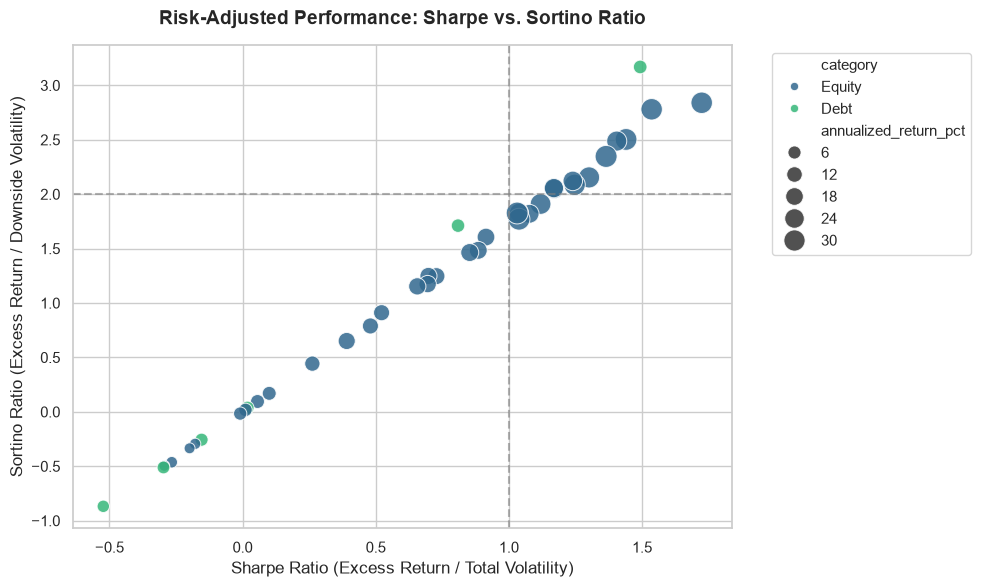

✓ Saved '01_sharpe_vs_sortino.png'


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'Arial', 'font.size': 11})

df_metrics = pd.read_csv("fund_sharpe_ranks.csv")

# 1. Sharpe vs Sortino Quadrant Scatter Plot
fig, ax = plt.subplots(figsize=(10, 6))
scatter = sns.scatterplot(
    data=df_metrics,
    x="sharpe_ratio",
    y="sortino_ratio",
    hue="category",
    size="annualized_return_pct",
    sizes=(60, 250),
    palette="viridis",
    alpha=0.85,
    ax=ax
)

ax.set_title("Risk-Adjusted Performance: Sharpe vs. Sortino Ratio", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Sharpe Ratio (Excess Return / Total Volatility)", fontsize=12)
ax.set_ylabel("Sortino Ratio (Excess Return / Downside Volatility)", fontsize=12)
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.6)
ax.axhline(2.0, color="gray", linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("01_sharpe_vs_sortino.png", dpi=300)
plt.show()

print("✓ Saved '01_sharpe_vs_sortino.png'")

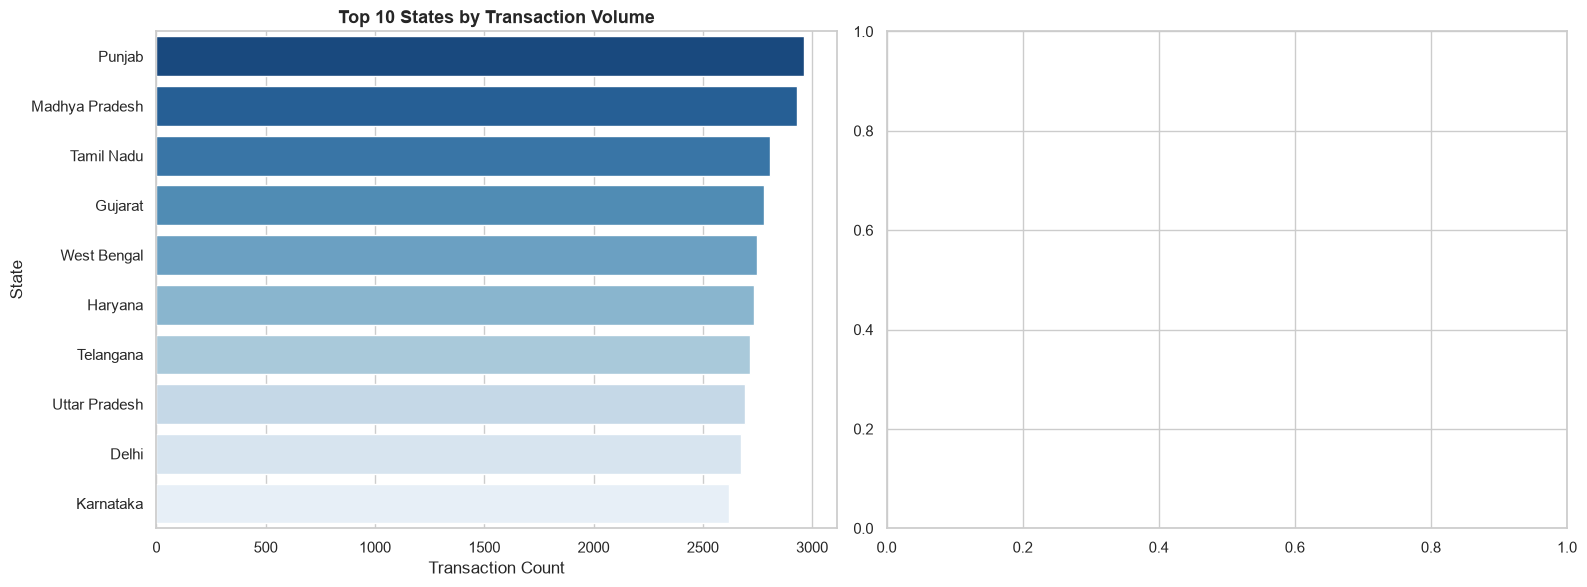

✓ Cleanly saved '02_investor_demographics.png' with no warnings!


In [22]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("mf_analytics.db")
df_tx = pd.read_sql("SELECT * FROM fact_transactions", conn)
conn.close()

# Standardize column headers
df_tx.columns = [c.strip().lower() for c in df_tx.columns]

# Create Figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. State Distribution (Top 10 States)
if "state" in df_tx.columns:
    state_counts = df_tx["state"].value_counts().head(10).reset_index()
    state_counts.columns = ["state", "count"]
    sns.barplot(
        data=state_counts,
        x="count",
        y="state",
        hue="state",
        palette="Blues_r",
        legend=False,
        ax=axes[0]
    )
    axes[0].set_title("Top 10 States by Transaction Volume", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Transaction Count")
    axes[0].set_ylabel("State")

# B. Age Distribution / Under-30 Metric
if "age" in df_tx.columns:
    df_tx["age_group"] = pd.cut(
        df_tx["age"],
        bins=[0, 30, 45, 60, 100],
        labels=["<30 Years", "30-45 Years", "46-60 Years", "60+ Years"]
    )
    age_dist = df_tx["age_group"].value_counts(normalize=True).mul(100).reset_index()
    age_dist.columns = ["age_group", "percentage"]
    
    sns.barplot(
        data=age_dist,
        x="age_group",
        y="percentage",
        hue="age_group",
        palette="crest",
        legend=False,
        ax=axes[1]
    )
    axes[1].set_title("Investor Age Group Distribution (%)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Age Group")
    axes[1].set_ylabel("Percentage (%)")
    for i, row in age_dist.iterrows():
        axes[1].text(i, row["percentage"] + 0.5, f"{row['percentage']:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("02_investor_demographics.png", dpi=300)
plt.show()

print("✓ Cleanly saved '02_investor_demographics.png' with no warnings!")

In [21]:
df_metrics = pd.read_csv("fund_sharpe_ranks.csv")

var_summary = df_metrics.groupby("category").agg(
    total_schemes=("amfi_code", "count"),
    avg_return_pct=("annualized_return_pct", "mean"),
    avg_volatility_pct=("annualized_volatility_pct", "mean"),
    avg_sharpe=("sharpe_ratio", "mean"),
    avg_sortino=("sortino_ratio", "mean"),
    worst_drawdown_pct=("max_drawdown_pct", "min"),
    avg_var_95_pct=("var_95_daily_pct", "mean")
).round(2).reset_index()

var_summary.to_csv("var_drawdown_summary.csv", index=False)
print("✓ Saved 'var_drawdown_summary.csv'!")
display(var_summary)

✓ Saved 'var_drawdown_summary.csv'!


,category,total_schemes,avg_return_pct,avg_volatility_pct,avg_sharpe,avg_sortino,worst_drawdown_pct,avg_var_95_pct
0,Debt,6,6.06,2.23,0.22,0.55,-8.32,-0.20
1,Equity,34,18.62,17.19,0.74,1.28,-52.57,-1.69


In [23]:
import sqlite3
import pandas as pd
import os

os.makedirs("dashboard_export", exist_ok=True)
conn = sqlite3.connect("mf_analytics.db")

tables = ["dim_fund", "fact_nav", "fact_transactions", "fact_holdings"]
for t in tables:
    df = pd.read_sql(f"SELECT * FROM {t}", conn)
    df.to_csv(f"dashboard_export/{t}.csv", index=False)
    print(f"✓ Exported dashboard_export/{t}.csv ({len(df):,} rows)")

conn.close()
print("\n✓ All datasets ready for your 4-page Power BI / Tableau Dashboard!")

✓ Exported dashboard_export/dim_fund.csv (40 rows)
✓ Exported dashboard_export/fact_nav.csv (46,000 rows)
✓ Exported dashboard_export/fact_transactions.csv (32,778 rows)
✓ Exported dashboard_export/fact_holdings.csv (322 rows)

✓ All datasets ready for your 4-page Power BI / Tableau Dashboard!
